# WSN Lab 1 — Temperature calibration (Section 9.1g)

Paired readings from the UNO R4 prototype's temperature channel and a
reference thermometer, taken at the same moment once both had settled.
The data lives in `data/calibration/calibration_pairs.csv`; add more rows
there and re-run to refine the model.

Two models are fitted:

- **Offset model** `T_cal = T_sensor + b` — the primary model. Its residuals describe the same two pairs used to fit the offset.
  They are fitting errors, not independent validation accuracy.
- **Linear model** `T_cal = a·T_sensor + b` — reported for completeness. With
  two pairs a line passes through both points exactly, so its "after" error
  is zero by construction and says nothing about accuracy. It needs five or
  more pairs across a wider range to be trustworthy.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("../data/calibration/calibration_pairs.csv")
s, r = df["sensor_c"].to_numpy(), df["thermometer_c"].to_numpy()
df["error_before"] = r - s
df

## Offset model (primary)

In [2]:
def mae(e):  return np.mean(np.abs(e))
def rmse(e): return np.sqrt(np.mean(e ** 2))

b = np.mean(r - s)
after = r - (s + b)
print(f"Offset b = {b:+.2f} C  (the sensor reads {b:.2f} C low on average)")
print(f"Before: MAE = {mae(r - s):.3f} C   RMSE = {rmse(r - s):.3f} C")
print(f"After : MAE = {mae(after):.3f} C   RMSE = {rmse(after):.3f} C")
print(f"MAE reduced by {(1 - mae(after)/mae(r - s))*100:.0f}%, RMSE by {(1 - rmse(after)/rmse(r - s))*100:.0f}%")

Offset b = +0.95 C  (the sensor reads 0.95 C low on average)
Before: MAE = 0.950 C   RMSE = 0.982 C
After : MAE = 0.250 C   RMSE = 0.250 C
MAE reduced by 74%, RMSE by 75%


## Linear model (needs more points to be reliable)

In [3]:
a, c = np.polyfit(s, r, 1)
print(f"Two-point line: T_cal = {a:.3f} * T_sensor + {c:.3f}")
print("Exact fit through both points -> residuals are zero by construction, not a measure of accuracy.")

Two-point line: T_cal = 0.881 * T_sensor + 4.545
Exact fit through both points -> residuals are zero by construction, not a measure of accuracy.


## Plot

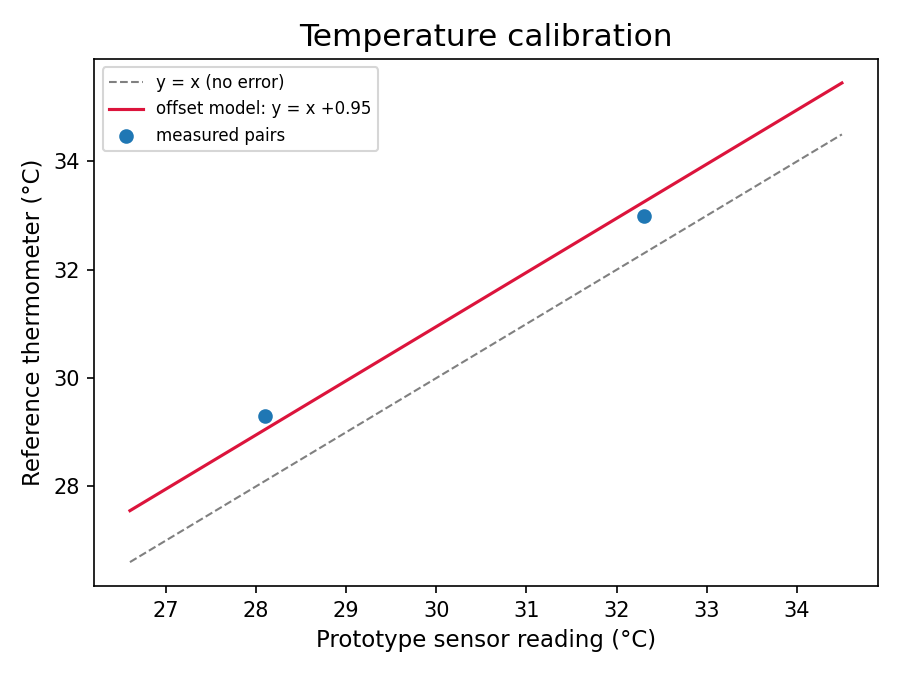

In [4]:
fig, ax = plt.subplots(figsize=(6, 4.5))
lo, hi = min(s.min(), r.min()) - 1.5, max(s.max(), r.max()) + 1.5
x = np.linspace(lo, hi, 50)
ax.plot(x, x, "--", color="gray", lw=1, label="y = x (no error)")
ax.plot(x, x + b, color="crimson", lw=1.5, label=f"offset model: y = x {b:+.2f}")
ax.scatter(s, r, zorder=3, label="measured pairs")
ax.set_xlabel("Prototype sensor reading (°C)")
ax.set_ylabel("Reference thermometer (°C)")
ax.set_title("Temperature calibration")
ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig("../figures/calibration_fit.png", dpi=150)
plt.show()